# Exercise 2.2 | Numerical Variables by Category

In this exercise, we'll explore how Starbucks customers respond to different promotional offers. The data contains customer interactions with various discount structures (BOGO, $2 off $10, $5 off $20, etc.).

**Key Question:** How does the incentive structure affect buying behavior?

In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load Data
file_path = 'https://econ-0150.tayweid.io/data/'
data = pd.read_csv(file_path + 'Starbucks_Promos.csv', index_col=0)
data.head()

,Event,Revenue,Offer ID
0,transaction,34.56,2off10
1,transaction,18.97,2off10
2,transaction,33.90,Bogo 5
3,transaction,18.01,Bogo 10
4,transaction,19.11,Bogo 10


## Revenue by Offer Type

Use one of our existing tools to visualize revenue by category to answer whether Bogo 5 or Bogo 10 has higher average spending.

<Axes: xlabel='Offer ID', ylabel='Revenue'>

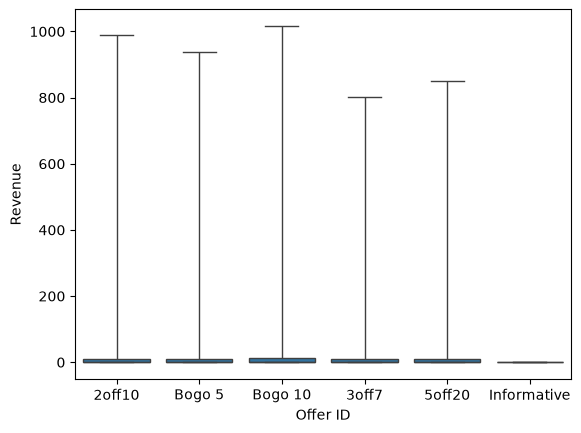

In [2]:
# Boxplot
sns.boxplot(data, x='Offer ID', y='Revenue', whis=(0,100))

## Log Transform for Skewed Data

When data is heavily skewed, a log transformation can help us see the distribution better. We'll use log base 2, where each unit represents a **doubling** of spending. Create a new column `log2_Revenue` equal to log2(1 + `Revenue`).

- log2(1+$7) = 3
- log2(1+$15) = 4
- log2(1+$31) = 5

In [3]:
data['log2_Revenue'] = np.log2(1 + data['Revenue'])

## Log Revenue by Offer Type

Create a boxplot with the log-transformed variable to better see the distribution.

Use `log2_Revenue` instead of `Revenue` on the y-axis.

<Axes: xlabel='Offer ID', ylabel='log2_Revenue'>

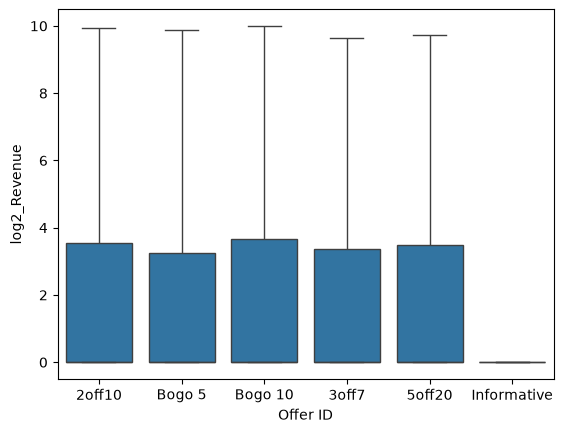

In [4]:
sns.boxplot(data, x='Offer ID', y='log2_Revenue', whis=(0,100))

## Investigate the Data

Count the unique values in the `Event` column to understand what's causing the zeros. Use `.value_counts()` to see how many of each event type we have.

In [5]:
data['Event'].value_counts()

Event
offer              76277
transaction        30617
offer completed     2962
Name: count, dtype: int64

## Filter for Transactions

Keep only rows where `Event` equals `'transaction'` to focus on actual purchases. Create a new dataframe called `transactions` with only the transaction rows.

In [6]:
transactions = data[data['Event'] == 'transaction']

## Visualize Filtered Data

Use the filtered `transactions` dataframe.

<Axes: xlabel='Offer ID', ylabel='log2_Revenue'>

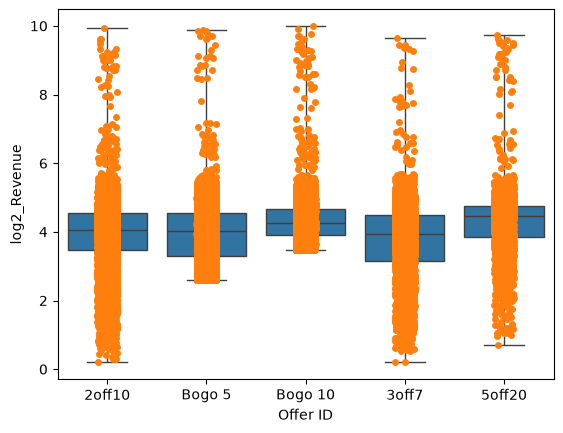

In [7]:
sns.boxplot(transactions, x='Offer ID', y='log2_Revenue', whis=(0,100))
sns.stripplot(transactions, x='Offer ID', y='log2_Revenue')

## Grouped Statistics

Calculate the mean, standard deviation, and count of log revenue by offer type. Use `.groupby()` and `.agg()` to compute multiple statistics at once.

In [8]:
transactions.groupby('Offer ID')['log2_Revenue'].agg(['mean', 'std', 'count'])

,mean,std,count
Offer ID,,,
2off10,3.887486,1.032985,8569
3off7,3.747167,1.061064,4698
5off20,4.306411,0.893283,3239
Bogo 10,4.332923,0.647303,6308
Bogo 5,3.953132,0.811144,7803


## Compare Two Offers

Filter for just Bogo 5 and Bogo 10, then create a boxplot to compare them. Use `.isin()` to filter for multiple values.

<Axes: xlabel='Offer ID', ylabel='log2_Revenue'>

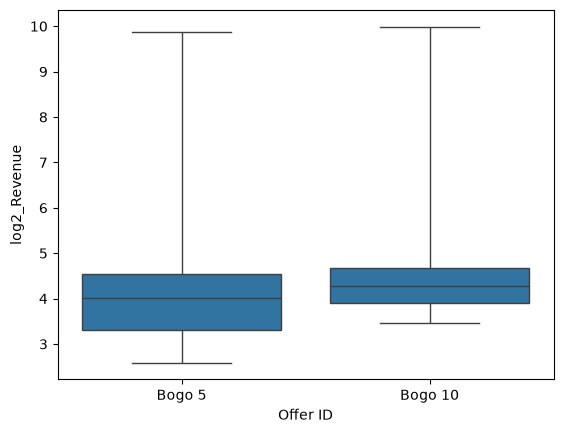

In [9]:
two_offers = transactions[transactions['Offer ID'].isin(['Bogo 5', 'Bogo 10'])]
sns.boxplot(two_offers, x='Offer ID', y='log2_Revenue', whis=(0,100))